# Exoplanet Classification v2 — Real Planet or False Positive?

**Data:** NASA Exoplanet Archive, Kepler Objects of Interest (KOI) cumulative table — 9,564 signals.

**Goal:** decide if a Kepler signal is a **real planet (CONFIRMED)** or a **FALSE POSITIVE**, using only the physical properties of the transit and its star. Then use the model to rank the **candidates** NASA has not decided on yet.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

## 1. Load the data
Downloaded straight from the NASA Exoplanet Archive (needs internet). To use a saved file, put its path in `DATA_PATH`.

In [5]:
DATA_PATH = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+*+from+cumulative&format=csv"
data = pd.read_csv(DATA_PATH)
print(data.shape)
data["koi_disposition"].value_counts()

(9564, 153)


koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

## 2. Why the `koi_fpflag_*` columns must go
Share of signals with at least one flag = 1, by class:

In [6]:
fp_flags = ["koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
data["any_flag"] = data[fp_flags].sum(axis=1) > 0
data.groupby("koi_disposition")["any_flag"].mean().round(3)

koi_disposition
CANDIDATE         0.002
CONFIRMED         0.007
FALSE POSITIVE    0.980
Name: any_flag, dtype: float64

Almost every false positive has a flag and almost no confirmed planet has one. The flags are NASA's decision, not a measurement, so they are not used as features.

## 3. Features: physical properties only
Transit properties (period, duration, depth, radius, ...) and star properties (temperature, gravity, radius, ...).

We leave out NASA's decisions (`koi_pdisposition`, `koi_score`, the flags), names and IDs (`kepler_name` is only filled for confirmed planets), and the centroid / pixel diagnostics, which are the inputs of the vetting flags.

In [7]:
features = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_prad", "koi_teq",
            "koi_insol", "koi_model_snr", "koi_ror", "koi_dor", "koi_srho", "koi_incl",
            "koi_num_transits", "koi_max_sngle_ev", "koi_max_mult_ev", "koi_bin_oedp_sig",
            "koi_steff", "koi_slogg", "koi_srad", "koi_smass", "koi_smet", "koi_kepmag"]

labelled = data[data["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
candidates = data[data["koi_disposition"] == "CANDIDATE"].copy()
labelled["y"] = (labelled["koi_disposition"] == "CONFIRMED").astype(int)

**Missing values are a hidden leak.** Some measurements are missing much more often for false positives, because NASA's pipeline often stops early on bad signals and never computes them. The table below shows the gap.

In [8]:
missing = labelled.groupby("koi_disposition")[features].apply(lambda g: g.isna().mean() * 100).T
missing.sort_values("FALSE POSITIVE", ascending=False).head(6).round(1)

koi_disposition,CONFIRMED,FALSE POSITIVE
koi_bin_oedp_sig,0.6,18.5
koi_num_transits,0.4,13.8
koi_max_sngle_ev,0.4,13.8
koi_max_mult_ev,0.4,13.8
koi_smet,0.1,5.7
koi_incl,0.1,5.3


**Why not impute them?** The values are *missing not at random*: being missing is itself caused by the signal looking like a false positive.
- Imputing does not remove that information. With a median fill, every missing row gets the same value, and a tree model can still spot it and learn "this was missing, so it is a false positive".
- The model would then copy NASA's pipeline decision instead of learning the physics.

So we keep only **complete rows**. The trade-off: the model covers fewer signals (only those with all 22 measurements), and the final score applies to that group.

In [9]:
labelled = labelled.dropna(subset=features)
candidates = candidates.dropna(subset=features)
print("labelled signals:", len(labelled), "| candidates:", len(candidates))
labelled["koi_disposition"].value_counts(normalize=True).round(3)

labelled signals: 6619 | candidates: 1369


koi_disposition
FALSE POSITIVE    0.588
CONFIRMED         0.412
Name: proportion, dtype: float64

## 4. Split by star
One star can have several signals with the **same star values**. If they are in both train and test, the model just recognises the star. So all signals of a star go to the same side.

In [10]:
X = labelled[features]
y = labelled["y"]
stars = labelled["kepid"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=stars))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
stars_train = stars.iloc[train_idx]

print("train:", len(X_train), "| test:", len(X_test))
print("stars in both train and test:", len(set(stars_train) & set(stars.iloc[test_idx])))

train: 5281 | test: 1338
stars in both train and test: 0


## 5. Choose the model with cross-validation (train set only)
5-fold CV, grouped by star. Metric: ROC-AUC.

In [11]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, groups=stars_train,
                             cv=GroupKFold(n_splits=5), scoring="roc_auc")
    cv_results[name] = scores.mean()
    print(f"{name}: CV ROC-AUC = {scores.mean():.3f} (+/- {scores.std():.3f})")

best_name = max(cv_results, key=cv_results.get)
print("\nBest model:", best_name)

Logistic Regression: CV ROC-AUC = 0.943 (+/- 0.009)
Random Forest: CV ROC-AUC = 0.975 (+/- 0.005)
Gradient Boosting: CV ROC-AUC = 0.978 (+/- 0.003)

Best model: Gradient Boosting


## 6. Final result on the test set (used once)

Accuracy: 0.936
F1:       0.926
ROC-AUC:  0.982

                precision    recall  f1-score   support

False positive       0.96      0.93      0.94       766
     Confirmed       0.91      0.95      0.93       572

      accuracy                           0.94      1338
     macro avg       0.93      0.94      0.93      1338
  weighted avg       0.94      0.94      0.94      1338



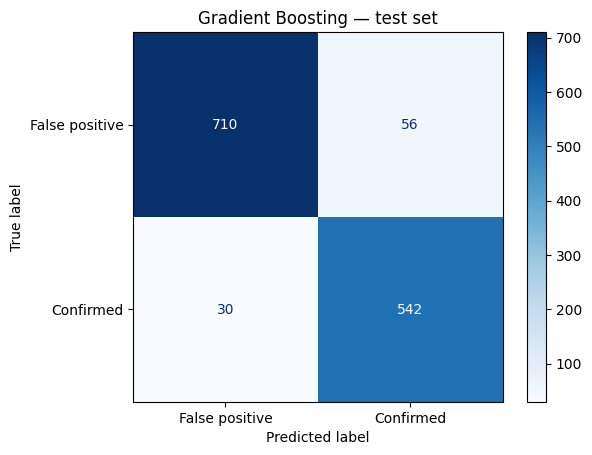

In [12]:
best_model = models[best_name].fit(X_train, y_train)
proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("F1:      ", round(f1_score(y_test, pred), 3))
print("ROC-AUC: ", round(roc_auc_score(y_test, proba), 3))
print()
print(classification_report(y_test, pred, target_names=["False positive", "Confirmed"]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["False positive", "Confirmed"], cmap="Blues")
plt.title(f"{best_name} — test set")
plt.show()

## 7. How much did v1's setup inflate the score?
v1-style: random split, all numeric columns **plus the flags**.

In [13]:
numeric = [c for c in data.select_dtypes(include="number").columns
           if c not in ["kepid", "rowid", "koi_score"] and data[c].nunique() > 1]
all_labelled = data[data["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])]
a_train, a_test, b_train, b_test = train_test_split(all_labelled[numeric], all_labelled["koi_disposition"],
                                                    test_size=0.2, random_state=42,
                                                    stratify=all_labelled["koi_disposition"])
v1_like = HistGradientBoostingClassifier(random_state=42).fit(a_train, b_train)

print("v1-style accuracy (flags + random split):", round(accuracy_score(b_test, v1_like.predict(a_test)), 3))
print("v2 accuracy (physics only + split by star):", round(accuracy_score(y_test, pred), 3))

v1-style accuracy (flags + random split): 0.997
v2 accuracy (physics only + split by star): 0.936


## 8. Which features matter?
Permutation importance on the test set: how much ROC-AUC drops when one feature is shuffled.

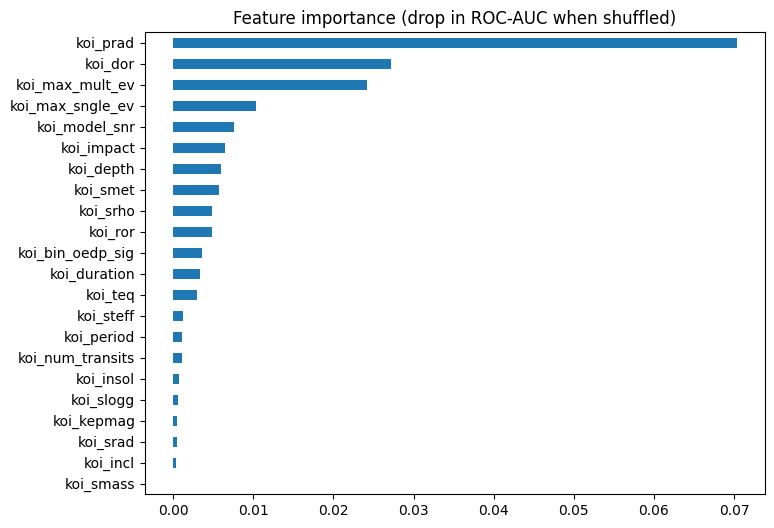

koi_prad            0.0703
koi_dor             0.0271
koi_max_mult_ev     0.0242
koi_max_sngle_ev    0.0104
koi_model_snr       0.0076
koi_impact          0.0065
koi_depth           0.0060
koi_smet            0.0057
dtype: float64

In [14]:
imp = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=42)
importance = pd.Series(imp.importances_mean, index=features).sort_values()

importance.plot.barh(figsize=(8, 6))
plt.title("Feature importance (drop in ROC-AUC when shuffled)")
plt.show()
importance.sort_values(ascending=False).head(8).round(4)

## 9. Rank the candidates
The real use of the model: give each CANDIDATE a probability of being a real planet, so the most promising ones can be followed up first.

Candidates scored: 1369
Probability > 0.9: 265
Probability < 0.1: 602


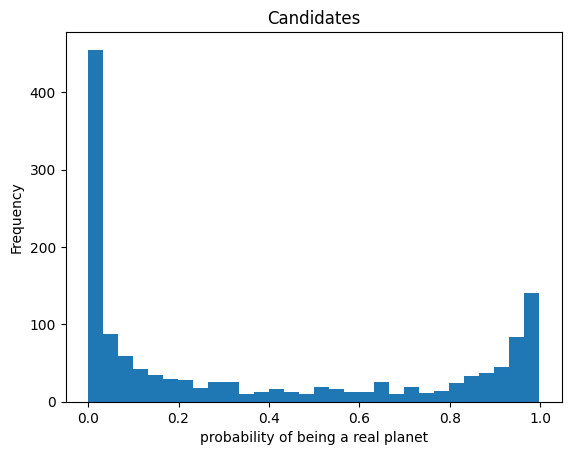

,kepoi_name,koi_period,koi_prad,planet_probability
5854,K03936.01,141.608555,2.98,0.997906
1182,K01656.01,51.390145,3.62,0.997480
882,K01399.01,8.750598,2.27,0.997100
2403,K00268.01,110.378383,3.02,0.996984
5012,K03460.01,62.596544,2.25,0.996713
2847,K02972.01,13.251121,1.98,0.996072
349,K00974.01,53.505761,2.52,0.996017
4424,K04526.01,30.539293,2.72,0.995638
1549,K02009.01,86.749081,2.23,0.995633
3767,K04037.01,215.956008,3.36,0.995229


In [15]:
candidates["planet_probability"] = best_model.predict_proba(candidates[features])[:, 1]

print("Candidates scored:", len(candidates))
print("Probability > 0.9:", (candidates["planet_probability"] > 0.9).sum())
print("Probability < 0.1:", (candidates["planet_probability"] < 0.1).sum())

candidates["planet_probability"].plot.hist(bins=30)
plt.xlabel("probability of being a real planet")
plt.title("Candidates")
plt.show()

candidates.sort_values("planet_probability", ascending=False)[["kepoi_name", "koi_period", "koi_prad", "planet_probability"]].head(10)

## 10. Summary
- The v1 score was inflated by NASA's vetting flags, signals from the same star in train and test, and choosing the model on the test set.
- With 22 physical features only, a split by star, and model selection by cross-validation, **Gradient Boosting** reaches **93.6% accuracy, F1 0.926, ROC-AUC 0.982** on unseen stars (v1-style setup: 99.7%).
- Most useful signals: planet radius, the star–planet distance ratio (`koi_dor`), and how strong the transit is (`koi_max_mult_ev`, `koi_model_snr`).
- Of 1,369 open candidates, 265 get a probability above 0.9 of being a real planet.

**Limitations**
- Only signals with all 22 measurements are used (6,619 of 7,587 labelled signals; 1,369 of 1,977 candidates), so the result applies to that group.
- Checked with 5 different star-based splits: accuracy stays between 92.9% and 94.0%.